# Réseau Analogique — Classification Disque — v5 (CONTRAINTE Itot ≥ 0)

**Problème** : classifier des points à l'intérieur vs l'extérieur d'un disque centré de rayon 0.5.

Accélérations :
  - `layer_forward`         : Numba JIT (`@njit`) — supprime la double boucle Python
  - `interp2d_bilinear`     : Numba JIT — interpolation compilée
  - `network_forward_mc`    : CuPy GPU — tirages Monte-Carlo en parallèle sur GPU
  - `coordinate_search`     : joblib — candidats évalués en parallèle sur N cœurs
  - `restarts`              : joblib — restarts indépendants en parallèle
  - `MIN_MARGIN_HZ = 1kHz`  : pénalité dure si marge < 1 kHz (contrainte physique)

**Fix v4.1** : Correction du comportement neuronal pour courants négatifs.  
Un neurone avec `Itot < I_rheobase` ne spike pas → `Fout = 0 Hz` (et non 3 kHz).

**Fix v5** : Contrainte physique `Itot ≥ 0` stricte.  
Un courant total négatif ne produit pas simplement `Fout = 0 Hz` — il sature/perturbe  
le circuit physique et fausse toute la chaîne en aval. Deux mécanismes :
  - **Pénalité dure** dans le score : `MIN_ITOT_PENALTY * frac_itot_neg`
  - **Filtre précoce** dans `coordinate_search` : tout candidat créant `Itot < 0`  
    est rejeté immédiatement sans évaluer le score complet (gain de vitesse).

Exécuter les cellules dans l'ordre (`Kernel → Restart & Run All`).  
Première exécution plus lente : Numba compile les fonctions JIT au premier appel.

## 0. Imports & Configuration

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
import time
import warnings
warnings.filterwarnings('ignore')

from numba import njit, prange
import joblib
from tqdm.auto import tqdm, trange
try:
    import cupy as cp
    GPU_AVAILABLE = True
    print('GPU détecté :', cp.cuda.runtime.getDeviceProperties(0)['name'].decode())
except Exception:
    cp = None
    GPU_AVAILABLE = False
    print('GPU non disponible — Monte-Carlo sur CPU.')

%matplotlib inline
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size']  = 11
np.set_printoptions(precision=4, suppress=True)

# ── Fichiers CSV ──────────────────────────────────────────────
INPUT_CSV   = 'input_min_conso.csv'
NEURON_CSV  = 'neuron.csv'
SYN_EXC_CSV = 'excitation20.csv'
SYN_INH_CSV = 'inhibition20.csv'

FREQ_MERGE_TOL_HZ = 1000.0

# ── Architecture  [2, N_hidden, 2] ───────────────────────────
HIDDEN_SIZES = [4,4]   # ex: [4] -> 2-4-2  |  [4,4] -> 2-4-4-2

# ── Recherche ────────────────────────────────────────────────
N_RESTARTS   = 8
MAX_PASSES   = 8
SEED         = 42
N_JOBS       = -1    # -1 = tous les cœurs CPU disponibles

# ── Dataset Disque ────────────────────────────────────────────
N_TRAIN     = 400
N_TEST      = 200
DISK_RADIUS = 0.5   # rayon du disque en coordonnées normalisées [-1, 1]
MARGIN      = 0.05  # zone d'exclusion autour du bord du disque

# ── Score avec contrainte physique 1 kHz ─────────────────────
# Plage fréquence hardware : 3 kHz – 193.1 kHz
MARGIN_SCALE       = 1e-4
IMBALANCE_PENALTY  = 0.15
MIN_MARGIN_HZ      = 1000.0
MIN_MARGIN_PENALTY = 0.5

# ── Contrainte Itot ≥ 0 (v5) ─────────────────────────────────
# Un courant négatif sature le circuit physique et perturbe toute la chaîne.
# Pénalité très forte pour forcer la recherche à l'éviter strictement.
MIN_ITOT_A       = 0.0    # seuil : Itot doit rester ≥ 0 A
MIN_ITOT_PENALTY = 1.0    # pénalité par fraction de neurones avec Itot < 0
                           # (plus forte que MIN_MARGIN_PENALTY=0.5)
# Fraction du dataset utilisée pour le filtre précoce (rapide, 20%)
ITOT_CHECK_FRAC  = 0.2

# ── Robustesse au bruit ───────────────────────────────────────
NOISE_STD_HZ = 500.0
N_MC_TRAIN   = 5
N_MC_EVAL    = 30

print('Configuration OK.')

GPU détecté : NVIDIA GeForce RTX 3080
Configuration OK.


## 1. Fonctions utilitaires

In [15]:
def progress_bar(current, total, prefix='', suffix='', bar_len=35):
    filled = int(bar_len * current / total)
    bar    = '█' * filled + '░' * (bar_len - filled)
    pct    = int(100 * current / total)
    sys.stdout.write('\r  ' + prefix + '[' + bar + '] '
                     + str(current) + '/' + str(total)
                     + ' (' + str(pct) + '%)  ' + suffix)
    sys.stdout.flush()
    if current == total:
        sys.stdout.write('\n')
        sys.stdout.flush()

def read_cadence_rows(csv_path):
    df = pd.read_csv(csv_path)
    if 'Parameter' not in df.columns:
        raise ValueError(csv_path + ": colonne 'Parameter' introuvable")
    data_cols = [c for c in df.columns if c not in ['Parameter', 'Unnamed: 1']]
    def get_row(row_name, allow_non_numeric=False):
        row = df.loc[df['Parameter'] == row_name, data_cols]
        if row.empty:
            raise ValueError("Ligne '" + row_name + "' introuvable dans " + csv_path)
        values = pd.to_numeric(row.iloc[0], errors='coerce').to_numpy(dtype=float)
        if not allow_non_numeric and np.isnan(values).any():
            raise ValueError("Ligne '" + row_name + "' contient des NaN")
        return values
    return get_row

def get_clean_rows(reader, row_names):
    rows = [reader(name, allow_non_numeric=True) for name in row_names]
    mask = np.all(np.isfinite(np.vstack(rows)), axis=0)
    return [r[mask] for r in rows], mask

def interp_clip(x, xp, fp):
    return np.interp(np.asarray(x, float), xp, fp, left=fp[0], right=fp[-1])

def strictly_monotonic_branch(x, y):
    idx = int(np.argmax(y))
    xm, ym = np.asarray(x[:idx+1], float), np.asarray(y[:idx+1], float)
    o = np.argsort(xm)
    return xm[o], ym[o]

def merge_close_values(values, tol):
    vals = np.sort(np.asarray(values, float))
    groups = [[vals[0]]]
    for v in vals[1:]:
        if abs(v - np.mean(groups[-1])) <= tol:
            groups[-1].append(v)
        else:
            groups.append([v])
    return np.array([np.mean(g) for g in groups])

def snap_to_axis(values, axis):
    return np.array([axis[np.argmin(np.abs(axis - v))]
                     for v in np.asarray(values, float)])

def build_grid_tolerant(W_all, F_all, Y_all, freq_tol=1000.0):
    W_all, F_all, Y_all = (np.asarray(a, float) for a in (W_all, F_all, Y_all))
    W_unique = np.unique(W_all)
    F_axis   = merge_close_values(np.unique(F_all), tol=freq_tol)
    F_snap   = snap_to_axis(F_all, F_axis)
    z_grid   = np.empty((len(W_unique), len(F_axis)))
    for i, w in enumerate(W_unique):
        for j, f in enumerate(F_axis):
            mask = np.isclose(W_all, w) & np.isclose(F_snap, f)
            if not mask.any():
                raise ValueError('Point manquant W=' + str(w) + ' F=' + str(f))
            z_grid[i, j] = np.mean(Y_all[mask])
    return W_unique, F_axis, z_grid

print('Fonctions utilitaires OK.')

Fonctions utilitaires OK.


## 2. Chargement des modèles Cadence

In [16]:
inp = read_cadence_rows(INPUT_CSV)
VEX_IN, FSPIKES_IN = inp('Vex'), inp('Fspikes')
INPUT_V_AXIS, INPUT_F_AXIS = strictly_monotonic_branch(VEX_IN, FSPIKES_IN)

neuro = read_cadence_rows(NEURON_CSV)
IEX_NEURO, FSPIKES_NEURO = neuro('Iex'), neuro('Fspikes')
NEURON_I_AXIS, NEURON_F_AXIS = strictly_monotonic_branch(IEX_NEURO, FSPIKES_NEURO)

syn_exc = read_cadence_rows(SYN_EXC_CSV)
(W2_EXC, FPRE_EXC, IPOST_EXC), _ = get_clean_rows(syn_exc, ['W2', 'Fpre', 'Ipost'])
W_EXC_AXIS, F_EXC_AXIS, IPOST_EXC_GRID = build_grid_tolerant(
    W2_EXC, FPRE_EXC, IPOST_EXC, FREQ_MERGE_TOL_HZ)

syn_inh = read_cadence_rows(SYN_INH_CSV)
(W2_INH, FPRE_INH, IPOST_INH), _ = get_clean_rows(syn_inh, ['W2', 'Fpre', 'Ipost'])
W_INH_AXIS, F_INH_AXIS, IPOST_INH_GRID = build_grid_tolerant(
    W2_INH, FPRE_INH, IPOST_INH, FREQ_MERGE_TOL_HZ)

V_MIN       = float(INPUT_V_AXIS[0])
V_MAX       = float(INPUT_V_AXIS[-1])
LAYER_SIZES = [2] + HIDDEN_SIZES + [2]

NEURON_I_RHEOBASE = float(NEURON_I_AXIS[0])

_INPUT_V_AXIS   = np.ascontiguousarray(INPUT_V_AXIS,   dtype=np.float64)
_INPUT_F_AXIS   = np.ascontiguousarray(INPUT_F_AXIS,   dtype=np.float64)
_NEURON_I_AXIS  = np.ascontiguousarray(NEURON_I_AXIS,  dtype=np.float64)
_NEURON_F_AXIS  = np.ascontiguousarray(NEURON_F_AXIS,  dtype=np.float64)
_W_EXC_AXIS     = np.ascontiguousarray(W_EXC_AXIS,     dtype=np.float64)
_F_EXC_AXIS     = np.ascontiguousarray(F_EXC_AXIS,     dtype=np.float64)
_IPOST_EXC_GRID = np.ascontiguousarray(IPOST_EXC_GRID, dtype=np.float64)
_W_INH_AXIS     = np.ascontiguousarray(W_INH_AXIS,     dtype=np.float64)
_F_INH_AXIS     = np.ascontiguousarray(F_INH_AXIS,     dtype=np.float64)
_IPOST_INH_GRID = np.ascontiguousarray(IPOST_INH_GRID, dtype=np.float64)
_F_MAX          = float(NEURON_F_AXIS[-1])

print('Input  V : ' + str(round(V_MIN*1e3,1)) + ' mV -> ' + str(round(V_MAX*1e3,1)) + ' mV')
print('Neuron I : ' + str(round(NEURON_I_AXIS[0]*1e12,1))
      + ' pA -> ' + str(round(NEURON_I_AXIS[-1]*1e12,1)) + ' pA')
print('Neuron rheobase (I_min spike) : ' + str(round(NEURON_I_RHEOBASE*1e12,2)) + ' pA')
print('Exc W (um) : ' + str(W_EXC_AXIS))
print('Inh W (um) : ' + str(W_INH_AXIS))
print('Architecture : ' + str(LAYER_SIZES))

Input  V : -100.0 mV -> 100.0 mV
Neuron I : 3.0 pA -> 1000.0 pA
Neuron rheobase (I_min spike) : 3.0 pA
Exc W (um) : [0.135  0.2858 0.4366 0.5874 0.7382 0.8889 1.04   1.191  1.341  1.492
 1.643  1.794  1.944  2.095  2.246  2.397  2.548  2.698  2.849  3.    ]
Inh W (um) : [0.135  0.1805 0.2261 0.2716 0.3171 0.3626 0.4082 0.4537 0.4992 0.5447
 0.5903 0.6358 0.6813 0.7268 0.7724 0.8179 0.8634 0.9089 0.9545 1.    ]
Architecture : [2, 4, 4, 2]


## 3. Noyaux Numba JIT

Ces fonctions sont compilées en C au premier appel (~2s), puis très rapides.

**Fix v4.1** : `_interp1d_numba` retourne maintenant `0.0` quand `x < xp[0]`  
(i.e. courant inférieur à la rheobase → neurone silencieux, pas de spiking).

In [17]:
@njit(cache=True)
def _interp1d_numba(x, xp, fp):
    """
    Interpolation 1D compilée Numba.
    FIX v4.1 : retourne 0.0 si x < xp[0] → neurone silencieux sous le seuil.
    """
    if x <= xp[0]:
        return 0.0
    if x >= xp[-1]:
        return fp[-1]
    lo, hi = 0, len(xp) - 1
    while hi - lo > 1:
        mid = (lo + hi) // 2
        if xp[mid] <= x:
            lo = mid
        else:
            hi = mid
    t = (x - xp[lo]) / (xp[hi] - xp[lo])
    return fp[lo] + t * (fp[hi] - fp[lo])


@njit(cache=True)
def _interp2d_numba(x, y, x_axis, y_axis, z_grid):
    """Interpolation bilinéaire compilée Numba."""
    x = max(x_axis[0], min(x_axis[-1], x))
    y = max(y_axis[0], min(y_axis[-1], y))
    lx, hx = 0, len(x_axis) - 2
    for k in range(len(x_axis) - 1):
        if x_axis[k] <= x < x_axis[k+1]:
            lx = k
            break
    else:
        lx = len(x_axis) - 2
    ly = 0
    for k in range(len(y_axis) - 1):
        if y_axis[k] <= y < y_axis[k+1]:
            ly = k
            break
    else:
        ly = len(y_axis) - 2
    x1, x2 = x_axis[lx], x_axis[lx+1]
    y1, y2 = y_axis[ly], y_axis[ly+1]
    tx = 0.0 if x2 == x1 else (x - x1) / (x2 - x1)
    ty = 0.0 if y2 == y1 else (y - y1) / (y2 - y1)
    return (z_grid[lx,   ly  ] * (1-tx) * (1-ty) +
            z_grid[lx+1, ly  ] * tx     * (1-ty) +
            z_grid[lx,   ly+1] * (1-tx) * ty     +
            z_grid[lx+1, ly+1] * tx     * ty)


@njit(cache=True, parallel=True)
def _layer_forward_numba(Fin, signs_flat, widths_flat, N, M,
                          w_exc, f_exc, g_exc,
                          w_inh, f_inh, g_inh,
                          ni_axis, nf_axis):
    """
    Layer forward entièrement compilé Numba avec parallélisme sur les synapses.
    """
    Iconn = np.zeros(N * M)
    for k in prange(N * M):
        i = k // M
        j = k  % M
        s = signs_flat[k]
        w = widths_flat[k]
        f = Fin[i]
        if s == 1:
            Iconn[k] = _interp2d_numba(w, f, w_exc, f_exc, g_exc)
        elif s == -1:
            Iconn[k] = -_interp2d_numba(w, f, w_inh, f_inh, g_inh)

    Itot = np.zeros(M)
    for k in range(N * M):
        j = k % M
        Itot[j] += Iconn[k]

    Fout = np.empty(M)
    for j in range(M):
        Fout[j] = _interp1d_numba(Itot[j], ni_axis, nf_axis)

    return Fout, Iconn.reshape((N, M)), Itot


def layer_forward(Fin_vec_Hz, sign_matrix, width_matrix_um):
    """Wrapper Python de _layer_forward_numba."""
    N, M = sign_matrix.shape
    Fout, Iconn, Itot = _layer_forward_numba(
        np.ascontiguousarray(Fin_vec_Hz, np.float64),
        sign_matrix.ravel().astype(np.float64),
        width_matrix_um.ravel().astype(np.float64),
        N, M,
        _W_EXC_AXIS, _F_EXC_AXIS, _IPOST_EXC_GRID,
        _W_INH_AXIS, _F_INH_AXIS, _IPOST_INH_GRID,
        _NEURON_I_AXIS, _NEURON_F_AXIS
    )
    return Fout, Iconn, Itot


def input_f_of_v(Vin_V):
    return float(_interp1d_numba(float(Vin_V), _INPUT_V_AXIS, _INPUT_F_AXIS))

def neuron_f_of_i(Iin_A):
    if Iin_A < NEURON_I_RHEOBASE:
        return 0.0
    return float(_interp1d_numba(float(Iin_A), _NEURON_I_AXIS, _NEURON_F_AXIS))

def isyn_exc(Fpre_Hz, Wexc_um):
    return float(_interp2d_numba(Wexc_um, Fpre_Hz, _W_EXC_AXIS, _F_EXC_AXIS, _IPOST_EXC_GRID))

def isyn_inh(Fpre_Hz, Winh_um):
    return float(_interp2d_numba(Winh_um, Fpre_Hz, _W_INH_AXIS, _F_INH_AXIS, _IPOST_INH_GRID))


# ── Warm-up Numba ──────────────────────────────────────────────
print('Compilation Numba JIT (une seule fois)...')
t0 = time.time()
_dummy_signs  = np.array([[1.0, -1.0], [-1.0, 1.0]])
_dummy_widths = np.array([[float(W_EXC_AXIS[0]), float(W_INH_AXIS[0])],
                           [float(W_INH_AXIS[0]), float(W_EXC_AXIS[0])]])
_dummy_F      = np.array([1000.0, 2000.0])
layer_forward(_dummy_F, _dummy_signs, _dummy_widths)
print(f'  JIT compilé en {time.time()-t0:.1f}s — les prochains appels seront rapides.')

print('\n── Vérification fix courant négatif ──')
print(f'  neuron_f_of_i(-1e-9 A)  = {neuron_f_of_i(-1e-9):.1f} Hz  (attendu: 0.0)')
print(f'  neuron_f_of_i(0.0 A)    = {neuron_f_of_i(0.0):.1f} Hz  (attendu: 0.0)')
print(f'  neuron_f_of_i(rheobase) = {neuron_f_of_i(NEURON_I_RHEOBASE):.1f} Hz  (attendu: ~{NEURON_F_AXIS[0]:.0f})')

print('\nNoyaux Numba OK.')

Compilation Numba JIT (une seule fois)...
  JIT compilé en 0.0s — les prochains appels seront rapides.

── Vérification fix courant négatif ──
  neuron_f_of_i(-1e-9 A)  = 0.0 Hz  (attendu: 0.0)
  neuron_f_of_i(0.0 A)    = 0.0 Hz  (attendu: 0.0)
  neuron_f_of_i(rheobase) = 0.0 Hz  (attendu: ~3083)

Noyaux Numba OK.


## 4. Propagation CPU + GPU

In [18]:
def network_forward_single(Vin_vec_V, signs, widths):
    """Forward pass déterministe, un seul sample."""
    F = np.array([input_f_of_v(v) for v in Vin_vec_V])
    for sm, wm in zip(signs, widths):
        F, _, _ = layer_forward(F, sm, wm)
    return F

def network_forward_dataset(V_dataset, signs, widths):
    """Forward déterministe sur tout le dataset."""
    return np.array([network_forward_single(Vin, signs, widths) for Vin in V_dataset])


def network_forward_with_itot(V_dataset, signs, widths):
    """
    Forward déterministe + collecte de TOUS les Itot intermédiaires.
    Retourne (Fout_array, all_itot_array).
    all_itot contient le courant total reçu par chaque neurone de chaque couche
    pour chaque sample — c'est la grandeur physique qui ne doit jamais être < 0.
    """
    all_itot = []
    Fouts = []
    for Vin in V_dataset:
        F = np.array([input_f_of_v(v) for v in Vin])
        for sm, wm in zip(signs, widths):
            F, _, Itot = layer_forward(F, sm, wm)
            all_itot.extend(Itot.tolist())
        Fouts.append(F)
    return np.array(Fouts), np.array(all_itot)


if GPU_AVAILABLE:
    def network_forward_mc(V_dataset, signs, widths, noise_std, n_mc):
        """Monte-Carlo sur GPU (CuPy). Clamp inférieur = 0.0."""
        N      = len(V_dataset)
        n_out  = LAYER_SIZES[-1]
        Fout_cpu = network_forward_dataset(V_dataset, signs, widths)
        Fout_gpu = cp.asarray(Fout_cpu)
        noise    = cp.random.normal(0.0, noise_std, (n_mc, N, n_out))
        Fout_mc  = cp.clip(Fout_gpu[None, :, :] + noise, 0.0, _F_MAX)
        return cp.asnumpy(Fout_mc.mean(axis=0))
else:
    def network_forward_mc(V_dataset, signs, widths, noise_std, n_mc):
        """Monte-Carlo CPU fallback. Clamp inférieur = 0.0."""
        rng = np.random.default_rng()
        acc = np.zeros((len(V_dataset), LAYER_SIZES[-1]))
        for _ in range(n_mc):
            Fout = network_forward_dataset(V_dataset, signs, widths)
            acc += np.clip(Fout + rng.normal(0, noise_std, Fout.shape), 0, _F_MAX)
        return acc / n_mc


print('Propagation OK.')

Propagation OK.


## 5. Dataset Disque

Train : 400 pts  cl1(int)=68  cl0(ext)=332
Test  : 200 pts  cl1(int)=40  cl0(ext)=160


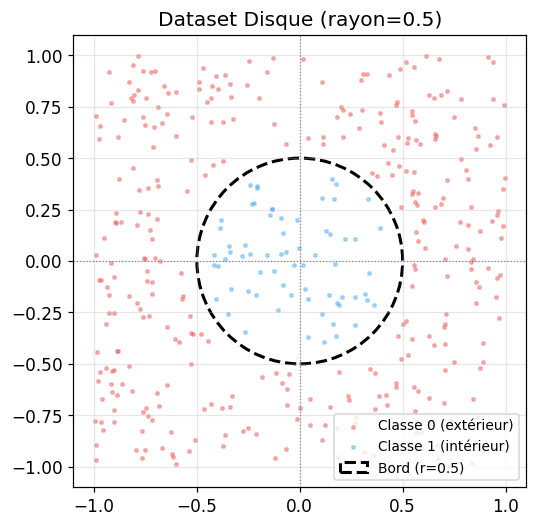

In [19]:
def label_disk(X, radius=DISK_RADIUS):
    """
    Classe 1 = intérieur du disque (r < radius)
    Classe 0 = extérieur du disque (r > radius)
    """
    return (X[:, 0]**2 + X[:, 1]**2 < radius**2).astype(int)

def make_dataset(n, seed=0):
    rng = np.random.default_rng(seed)
    pts = []
    while sum(len(p) for p in pts) < n:
        batch = rng.uniform(-1.0, 1.0, size=(n * 2, 2))
        # Exclure les points trop proches du bord du disque (zone ambiguë)
        r    = np.sqrt(batch[:, 0]**2 + batch[:, 1]**2)
        mask = np.abs(r - DISK_RADIUS) > MARGIN
        pts.append(batch[mask])
    data = np.vstack(pts)[:n]
    return data, label_disk(data)

def xy_to_voltage(X):
    return V_MIN + (np.asarray(X, float) + 1.0) * (V_MAX - V_MIN) / 2.0

X_train, y_train = make_dataset(N_TRAIN, seed=SEED)
X_test,  y_test  = make_dataset(N_TEST,  seed=SEED + 1)
V_train = xy_to_voltage(X_train)
V_test  = xy_to_voltage(X_test)

print('Train : ' + str(len(y_train)) + ' pts  cl1(int)=' + str(y_train.sum())
      + '  cl0(ext)=' + str((1-y_train).sum()))
print('Test  : ' + str(len(y_test))  + ' pts  cl1(int)=' + str(y_test.sum())
      + '  cl0(ext)=' + str((1-y_test).sum()))

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(X_train[y_train==0, 0], X_train[y_train==0, 1],
           s=5, alpha=0.4, c='#EF5350', label='Classe 0 (extérieur)')
ax.scatter(X_train[y_train==1, 0], X_train[y_train==1, 1],
           s=5, alpha=0.4, c='#42A5F5', label='Classe 1 (intérieur)')
circle = plt.Circle((0, 0), DISK_RADIUS, color='k', fill=False, lw=2, ls='--',
                    label=f'Bord (r={DISK_RADIUS})')
ax.add_patch(circle)
ax.axhline(0, color='gray', lw=0.8, ls=':')
ax.axvline(0, color='gray', lw=0.8, ls=':')
ax.set_title(f'Dataset Disque (rayon={DISK_RADIUS})')
ax.set_aspect('equal')
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Évaluation avec contrainte 1 kHz + contrainte Itot ≥ 0 (v5)

**Nouveau en v5** : `evaluate_network` collecte maintenant tous les `Itot` intermédiaires  
et ajoute une pénalité `MIN_ITOT_PENALTY * frac_itot_neg` au score.  
Un réseau avec des `Itot < 0` recevra un score fortement dégradé même s'il classe bien.

In [20]:
def evaluate_network(V_dataset, y_true, signs, widths,
                     noise_std=0.0, n_mc=1):
    """
    noise_std=0, n_mc=1  ->  déterministe.
    noise_std>0, n_mc>1  ->  Monte-Carlo GPU si disponible.

    Score = bal_acc
            + MARGIN_SCALE    * bal_margin          (récompense grande marge)
            - IMBALANCE_PENALTY * |acc0-acc1|        (pénalise déséquilibre classes)
            - MIN_MARGIN_PENALTY * frac_below_1kHz  (pénalité dure marge < 1kHz)
            - MIN_ITOT_PENALTY  * frac_itot_neg     (pénalité dure Itot < 0) [v5]
    """
    # Forward + collecte Itot (toujours en déterministe pour les Itot)
    Fout, all_itot = network_forward_with_itot(V_dataset, signs, widths)

    # Monte-Carlo pour les sorties si demandé
    if noise_std > 0 and n_mc > 1:
        Fout = network_forward_mc(V_dataset, signs, widths, noise_std, n_mc)

    preds = np.argmax(Fout, axis=1)
    y     = np.asarray(y_true, int)
    mask0, mask1 = (y == 0), (y == 1)

    acc0 = float(np.mean(preds[mask0] == 0)) if mask0.any() else 0.0
    acc1 = float(np.mean(preds[mask1] == 1)) if mask1.any() else 0.0
    bal_acc = 0.5 * (acc0 + acc1)

    margins = np.where(y == 1,
                       Fout[:, 1] - Fout[:, 0],
                       Fout[:, 0] - Fout[:, 1])
    margin0    = float(np.mean(margins[mask0])) if mask0.any() else 0.0
    margin1    = float(np.mean(margins[mask1])) if mask1.any() else 0.0
    bal_margin = 0.5 * (margin0 + margin1)

    frac_below_margin = float(np.mean(margins < MIN_MARGIN_HZ))

    # ── Contrainte Itot ≥ 0 (v5) ─────────────────────────────
    # frac_itot_neg = fraction de neurones (toutes couches, tous samples)
    # qui reçoivent un courant total négatif → saturation physique.
    frac_itot_neg = float(np.mean(all_itot < MIN_ITOT_A))

    score = (bal_acc
             + MARGIN_SCALE       * bal_margin
             - IMBALANCE_PENALTY  * abs(acc0 - acc1)
             - MIN_MARGIN_PENALTY * frac_below_margin
             - MIN_ITOT_PENALTY   * frac_itot_neg)   # ← nouveau terme v5

    return {'preds': preds, 'Fout': Fout,
            'acc0': acc0, 'acc1': acc1, 'bal_acc': bal_acc,
            'bal_margin': bal_margin,
            'frac_below': frac_below_margin,
            'frac_itot_neg': frac_itot_neg,           # ← nouveau champ v5
            'score': score}


def print_results(label, m):
    print('\n=== ' + label + ' ===')
    print('  acc cl0 (ext)   = ' + str(round(m['acc0'], 4)))
    print('  acc cl1 (int)   = ' + str(round(m['acc1'], 4)))
    print('  bal_acc         = ' + str(round(m['bal_acc'], 4)))
    print('  marge moy.      = ' + str(round(m['bal_margin'] * 1e-3, 3)) + ' kHz')
    print('  pts < 1 kHz     = ' + str(round(m['frac_below'] * 100, 1)) + ' %')
    print('  Itot < 0        = ' + str(round(m['frac_itot_neg'] * 100, 2)) + ' %  ← contrainte v5')
    print('  score           = ' + str(round(m['score'], 6)))


ALL_CANDIDATES = [
    [(+1, float(w)) for w in W_EXC_AXIS] + [(-1, float(w)) for w in W_INH_AXIS]
    for _ in range(len(LAYER_SIZES) - 1)
]
print('Candidats par connexion : ' + str(len(ALL_CANDIDATES[0]))
      + ' (' + str(len(W_EXC_AXIS)) + ' EXC + ' + str(len(W_INH_AXIS)) + ' INH)')


def random_network(rng):
    signs, widths = [], []
    for li, (n_in, n_out) in enumerate(zip(LAYER_SIZES[:-1], LAYER_SIZES[1:])):
        exc_w = [c[1] for c in ALL_CANDIDATES[li] if c[0] == +1]
        inh_w = [c[1] for c in ALL_CANDIDATES[li] if c[0] == -1]
        s = rng.choice([-1, 1], size=(n_in, n_out))
        w = np.zeros((n_in, n_out))
        for i in range(n_in):
            for j in range(n_out):
                w[i, j] = rng.choice(exc_w if s[i, j] == 1 else inh_w)
        signs.append(s)
        widths.append(w)
    return signs, widths

print('evaluate_network OK.')

Candidats par connexion : 40 (20 EXC + 20 INH)
evaluate_network OK.


## 7. coordinate_search (un seul restart)

**Nouveau en v5** : filtre précoce `_itot_is_valid` dans la boucle interne.  
Avant d'évaluer le score complet d'un candidat, on vérifie rapidement (sur 20% du dataset)  
qu'il ne crée aucun `Itot < 0`. Si la vérification échoue, le candidat est rejeté immédiatement  
sans appel à `evaluate_network` — gain de vitesse significatif sur les mauvais candidats.

In [21]:
# Sous-ensemble fixe pour le filtre précoce (20% du train, calculé une seule fois)
_N_ITOT_CHECK = max(10, int(len(V_train) * ITOT_CHECK_FRAC))
_V_ITOT_CHECK = V_train[:_N_ITOT_CHECK]
print(f'Filtre Itot précoce : {_N_ITOT_CHECK} samples ({ITOT_CHECK_FRAC*100:.0f}% du train)')


def _itot_is_valid(signs, widths):
    """
    Vérifie rapidement (sous-ensemble 20%) qu'aucun Itot n'est < 0.
    Retourne True si le réseau est physiquement valide (aucun courant négatif).
    Appelé avant evaluate_network pour rejeter rapidement les candidats invalides.
    """
    _, all_itot = network_forward_with_itot(_V_ITOT_CHECK, signs, widths)
    return bool(np.all(all_itot >= MIN_ITOT_A))


def _one_restart(restart_idx, rng_seed, pbar_restarts=None):
    """
    Un restart complet de coordinate search avec contrainte Itot ≥ 0 (v5).
    """
    rng = np.random.default_rng(rng_seed)
    all_conns = [
        (l, i, j)
        for l, (n_in, n_out) in enumerate(zip(LAYER_SIZES[:-1], LAYER_SIZES[1:]))
        for i in range(n_in)
        for j in range(n_out)
    ]
    n_conns = len(all_conns)

    # Initialisation : on cherche un réseau de départ avec Itot >= 0
    # Si le réseau aléatoire initial viole la contrainte, on le pénalise
    # mais on ne bloque pas (le score dégradé orientera la recherche)
    signs, widths = random_network(rng)
    tr = evaluate_network(V_train, y_train, signs, widths,
                          noise_std=NOISE_STD_HZ, n_mc=N_MC_TRAIN)
    va = evaluate_network(V_test,  y_test,  signs, widths)

    history = [{'pass': 0,
                'tr_bal_acc': tr['bal_acc'], 'tr_score': tr['score'],
                'va_bal_acc': va['bal_acc'], 'va_score': va['score'],
                'va_itot_neg_pct': va['frac_itot_neg'] * 100}]
    t0 = time.time()

    R = f'R{restart_idx+1:02d}'
    print(f'  {R} démarré | tr_acc={tr["bal_acc"]:.3f} | va_acc={va["bal_acc"]:.3f} '
          f'| Itot<0={tr["frac_itot_neg"]*100:.1f}%')

    for pass_idx in range(MAX_PASSES):
        improved   = False
        conn_order = list(all_conns)
        rng.shuffle(conn_order)
        t_pass = time.time()
        n_filtered = 0   # compteur de candidats rejetés par filtre Itot

        for conn_num, (l, i, j) in enumerate(conn_order):
            orig_s = signs[l][i, j]
            orig_w = widths[l][i, j]
            best_s, best_w, best_c = orig_s, orig_w, tr['score']

            for cs, cw in ALL_CANDIDATES[l]:
                if cs == orig_s and np.isclose(cw, orig_w):
                    continue

                # Appliquer le candidat temporairement
                signs[l][i, j]  = cs
                widths[l][i, j] = cw

                # ── Filtre précoce Itot ≥ 0 (v5) ─────────────────────────
                # Vérification rapide sur 20% du dataset avant évaluation complète.
                # Si ce candidat crée un Itot < 0 quelque part, on le rejette
                # immédiatement sans appeler evaluate_network (économie de temps).
                if not _itot_is_valid(signs, widths):
                    n_filtered += 1
                    signs[l][i, j]  = orig_s   # restaurer
                    widths[l][i, j] = orig_w
                    continue
                # ── Fin filtre ────────────────────────────────────────────

                ctr = evaluate_network(V_train, y_train, signs, widths,
                                       noise_std=NOISE_STD_HZ, n_mc=N_MC_TRAIN)
                if ctr['score'] > best_c:
                    best_c, best_s, best_w = ctr['score'], cs, cw

                signs[l][i, j]  = orig_s   # restaurer
                widths[l][i, j] = orig_w

            signs[l][i, j]  = best_s
            widths[l][i, j] = best_w
            if best_c > tr['score']:
                tr       = evaluate_network(V_train, y_train, signs, widths,
                                            noise_std=NOISE_STD_HZ, n_mc=N_MC_TRAIN)
                improved = True

        va = evaluate_network(V_test, y_test, signs, widths)
        history.append({'pass': pass_idx + 1,
                        'tr_bal_acc': tr['bal_acc'], 'tr_score': tr['score'],
                        'va_bal_acc': va['bal_acc'], 'va_score': va['score'],
                        'va_itot_neg_pct': va['frac_itot_neg'] * 100})

        elapsed_pass = time.time() - t_pass
        status = 'converge' if not improved else ''
        print(f'  {R} pass {pass_idx+1}/{MAX_PASSES} | '
              f'tr={tr["bal_acc"]:.3f} va={va["bal_acc"]:.3f} | '
              f'marge={va["bal_margin"]*1e-3:.1f}kHz | '
              f'<1kHz={va["frac_below"]*100:.0f}% | '
              f'Itot<0={va["frac_itot_neg"]*100:.1f}% | '
              f'filtrés={n_filtered} | '
              f'{elapsed_pass:.0f}s {status}')

        if not improved:
            break

    elapsed = time.time() - t0
    print(f'  ✓ {R} FINI | va_acc={va["bal_acc"]:.4f} | '
          f'marge={va["bal_margin"]*1e-3:.1f}kHz | '
          f'Itot<0={va["frac_itot_neg"]*100:.2f}% | {elapsed:.0f}s')

    if pbar_restarts is not None:
        pbar_restarts.update(1)

    return {
        'signs':    [s.copy() for s in signs],
        'widths':   [w.copy() for w in widths],
        'va_score': va['score'],
        'tr_score': tr['score'],
        'history':  history,
    }


def coordinate_search():
    """Lance N_RESTARTS restarts en parallèle via joblib."""
    seeds = [SEED + r * 1000 for r in range(N_RESTARTS)]

    pbar_restarts = tqdm(
        total=N_RESTARTS, leave=True,
        desc='Restarts terminés',
        bar_format='{l_bar}{bar}| {n}/{total} [{elapsed}]'
    )

    results = joblib.Parallel(n_jobs=N_JOBS, prefer='threads')(
        joblib.delayed(_one_restart)(r, seeds[r], pbar_restarts)
        for r in range(N_RESTARTS)
    )

    pbar_restarts.close()

    best = max(results, key=lambda r: (r['va_score'], r['tr_score']))
    print(f'\n★ Meilleur restart : va_score={best["va_score"]:.5f}')
    return best['signs'], best['widths'], best['history']

Filtre Itot précoce : 80 samples (20% du train)


## 8. Entraînement

In [22]:
n_conn = sum(LAYER_SIZES[i] * LAYER_SIZES[i+1] for i in range(len(LAYER_SIZES) - 1))
print('Architecture    : ' + str(LAYER_SIZES))
print('Problème        : Disque centré (r=' + str(DISK_RADIUS) + ')')
print('Restarts        : ' + str(N_RESTARTS) + '  (parallèles)')
print('Max passes      : ' + str(MAX_PASSES))
print('Connexions      : ' + str(n_conn))
print('Candidats/conn  : ' + str(len(ALL_CANDIDATES[0])))
print('NOISE_STD_HZ    : ' + str(NOISE_STD_HZ) + ' Hz')
print('MIN_MARGIN_HZ   : ' + str(MIN_MARGIN_HZ) + ' Hz')
print('MIN_ITOT_A      : ' + str(MIN_ITOT_A) + ' A  (contrainte v5 — Itot ≥ 0)')
print('MIN_ITOT_PENALTY: ' + str(MIN_ITOT_PENALTY))
print('GPU MC          : ' + str(GPU_AVAILABLE))

signs, widths, history = coordinate_search()

Architecture    : [2, 4, 4, 2]
Problème        : Disque centré (r=0.5)
Restarts        : 8  (parallèles)
Max passes      : 8
Connexions      : 32
Candidats/conn  : 40
NOISE_STD_HZ    : 500.0 Hz
MIN_MARGIN_HZ   : 1000.0 Hz
MIN_ITOT_A      : 0.0 A  (contrainte v5 — Itot ≥ 0)
MIN_ITOT_PENALTY: 1.0
GPU MC          : True


Restarts terminés:   0%|          | 0/8 [00:00]

  R04 démarré | tr_acc=0.505 | va_acc=0.500 | Itot<0=10.0%
  R06 démarré | tr_acc=0.467 | va_acc=0.500 | Itot<0=8.9%
  R03 démarré | tr_acc=0.500 | va_acc=0.500 | Itot<0=20.0%
  R08 démarré | tr_acc=0.530 | va_acc=0.500 | Itot<0=9.6%
  R01 démarré | tr_acc=0.500 | va_acc=0.500 | Itot<0=10.0%
  R07 démarré | tr_acc=0.567 | va_acc=0.500 | Itot<0=20.0%
  R05 démarré | tr_acc=0.473 | va_acc=0.500 | Itot<0=10.0%
  R02 démarré | tr_acc=0.488 | va_acc=0.500 | Itot<0=10.0%


Restarts terminés:  25%|██▌       | 2/8 [00:59]

  R07 pass 1/8 | tr=0.567 va=0.500 | marge=0.0kHz | <1kHz=100% | Itot<0=20.0% | filtrés=1248 | 59s converge
  ✓ R07 FINI | va_acc=0.5000 | marge=0.0kHz | Itot<0=20.00% | 59s
  R03 pass 1/8 | tr=0.500 va=0.500 | marge=0.0kHz | <1kHz=20% | Itot<0=20.0% | filtrés=1248 | 59s converge
  ✓ R03 FINI | va_acc=0.5000 | marge=0.0kHz | Itot<0=20.00% | 59s
  R02 pass 1/8 | tr=0.490 va=0.500 | marge=0.0kHz | <1kHz=100% | Itot<0=0.0% | filtrés=955 | 170s 
  R05 pass 1/8 | tr=0.553 va=0.500 | marge=0.0kHz | <1kHz=100% | Itot<0=0.0% | filtrés=699 | 267s 
  R01 pass 1/8 | tr=0.500 va=0.500 | marge=1.3kHz | <1kHz=20% | Itot<0=0.0% | filtrés=324 | 409s 
  R04 pass 1/8 | tr=0.500 va=0.500 | marge=0.4kHz | <1kHz=20% | Itot<0=0.0% | filtrés=209 | 452s 
  R06 pass 1/8 | tr=0.500 va=0.500 | marge=0.1kHz | <1kHz=20% | Itot<0=0.0% | filtrés=158 | 472s 
  R08 pass 1/8 | tr=0.518 va=0.500 | marge=0.0kHz | <1kHz=100% | Itot<0=0.0% | filtrés=144 | 478s 
  R02 pass 2/8 | tr=0.500 va=0.500 | marge=0.2kHz | <1kHz=20% 

Restarts terminés:  38%|███▊      | 3/8 [25:38]

... (7 outputs left out)

Restarts terminés:  88%|████████▊ | 7/8 [45:30]

  R05 pass 8/8 | tr=0.685 va=0.747 | marge=0.4kHz | <1kHz=61% | Itot<0=0.0% | filtrés=162 | 206s 
  ✓ R05 FINI | va_acc=0.7469 | marge=0.4kHz | Itot<0=0.00% | 2730s


Restarts terminés: 100%|██████████| 8/8 [46:01]

  R08 pass 8/8 | tr=0.769 va=0.816 | marge=0.6kHz | <1kHz=65% | Itot<0=0.0% | filtrés=103 | 151s 
  ✓ R08 FINI | va_acc=0.8156 | marge=0.6kHz | Itot<0=0.00% | 2761s

★ Meilleur restart : va_score=0.72800


## 9. Résultats


=== TRAIN (déterministe) ===
  acc cl0 (ext)   = 0.5843
  acc cl1 (int)   = 0.9265
  bal_acc         = 0.7554
  marge moy.      = 2.069 kHz
  pts < 1 kHz     = 41.2 %
  Itot < 0        = 0.0 %  ← contrainte v5
  score           = 0.704762

=== TEST  (déterministe) ===
  acc cl0 (ext)   = 0.6062
  acc cl1 (int)   = 0.925
  bal_acc         = 0.7656
  marge moy.      = 2.102 kHz
  pts < 1 kHz     = 40.0 %
  Itot < 0        = 0.0 %  ← contrainte v5
  score           = 0.728003

=== TRAIN (robuste MC) ===
  acc cl0 (ext)   = 0.5843
  acc cl1 (int)   = 0.9412
  bal_acc         = 0.7628
  marge moy.      = 2.045 kHz
  pts < 1 kHz     = 41.0 %
  Itot < 0        = 0.0 %  ← contrainte v5
  score           = 0.708682

=== TEST  (robuste MC) ===
  acc cl0 (ext)   = 0.6
  acc cl1 (int)   = 0.95
  bal_acc         = 0.775
  marge moy.      = 2.077 kHz
  pts < 1 kHz     = 39.5 %
  Itot < 0        = 0.0 %  ← contrainte v5
  score           = 0.732658


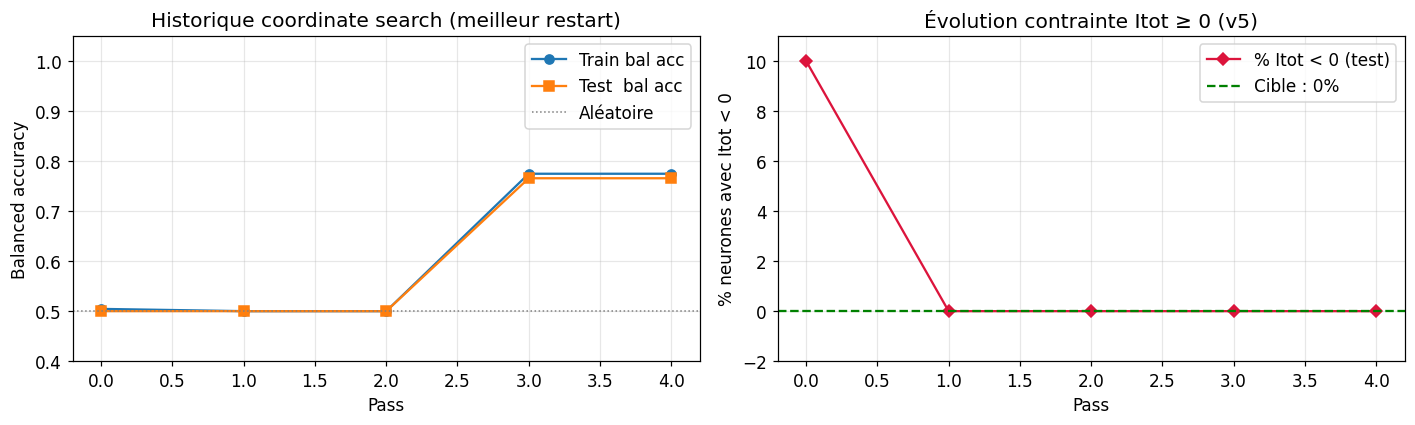

In [23]:
m_train = evaluate_network(V_train, y_train, signs, widths)
m_test  = evaluate_network(V_test,  y_test,  signs, widths)
print_results('TRAIN (déterministe)', m_train)
print_results('TEST  (déterministe)', m_test)

m_train_rob = evaluate_network(V_train, y_train, signs, widths,
                                noise_std=NOISE_STD_HZ, n_mc=N_MC_EVAL)
m_test_rob  = evaluate_network(V_test,  y_test,  signs, widths,
                                noise_std=NOISE_STD_HZ, n_mc=N_MC_EVAL)
print_results('TRAIN (robuste MC)', m_train_rob)
print_results('TEST  (robuste MC)', m_test_rob)

if history:
    passes = [h['pass'] for h in history]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    ax = axes[0]
    ax.plot(passes, [h['tr_bal_acc'] for h in history], 'o-', label='Train bal acc')
    ax.plot(passes, [h['va_bal_acc'] for h in history], 's-', label='Test  bal acc')
    ax.axhline(0.5, color='gray', ls=':', lw=1, label='Aléatoire')
    ax.set_xlabel('Pass')
    ax.set_ylabel('Balanced accuracy')
    ax.set_title('Historique coordinate search (meilleur restart)')
    ax.set_ylim(0.4, 1.05)
    ax.legend()
    ax.grid(True, alpha=0.3)

    ax = axes[1]
    ax.plot(passes, [h['va_itot_neg_pct'] for h in history],
            'D-', color='crimson', label='% Itot < 0 (test)')
    ax.axhline(0, color='green', ls='--', lw=1.5, label='Cible : 0%')
    ax.set_xlabel('Pass')
    ax.set_ylabel('% neurones avec Itot < 0')
    ax.set_title('Évolution contrainte Itot ≥ 0 (v5)')
    ax.set_ylim(-2, max(5, max(h['va_itot_neg_pct'] for h in history) * 1.1))
    ax.legend()
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

## 10. Carte de décision

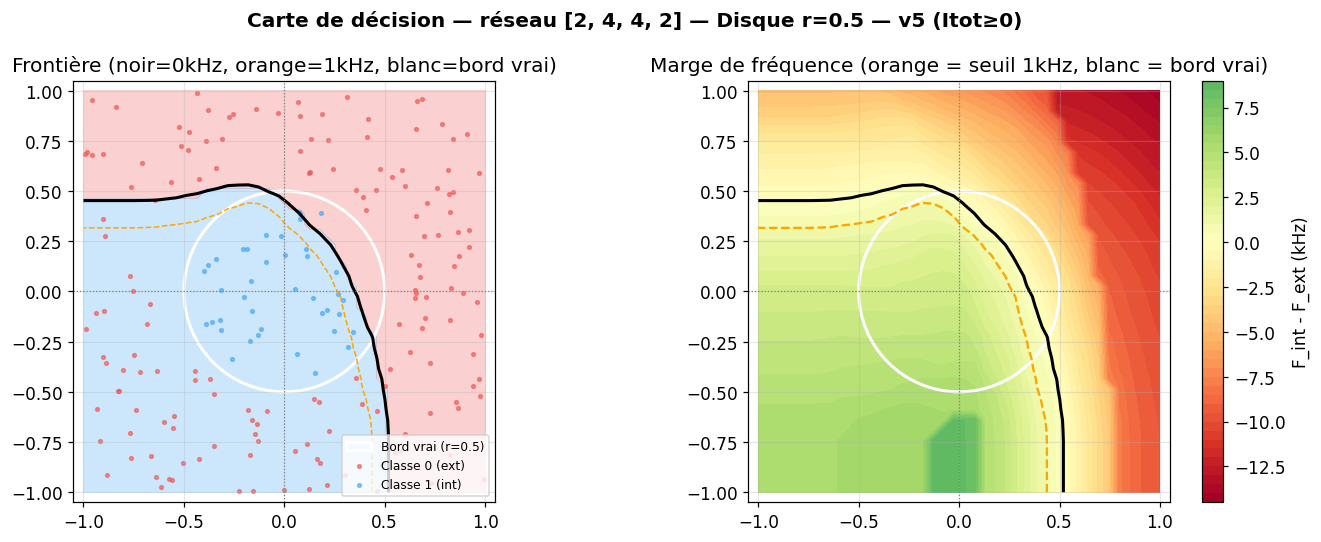

In [24]:
resolution = 40
xs = np.linspace(-1, 1, resolution)
ys = np.linspace(-1, 1, resolution)
XX, YY = np.meshgrid(xs, ys)
grid_V = xy_to_voltage(np.column_stack([XX.ravel(), YY.ravel()]))

Fout_grid   = network_forward_dataset(grid_V, signs, widths)
pred_grid   = np.argmax(Fout_grid, axis=1).reshape(XX.shape)
margin_grid = (Fout_grid[:, 1] - Fout_grid[:, 0]).reshape(XX.shape) * 1e-3

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle(f'Carte de décision — réseau {LAYER_SIZES} — Disque r={DISK_RADIUS} — v5 (Itot≥0)',
             fontweight='bold')

ax = axes[0]
ax.contourf(XX, YY, pred_grid, levels=[-0.5, 0.5, 1.5],
            colors=['#EF535044', '#42A5F544'])
ax.contour(XX, YY, margin_grid, levels=[0], colors='k', linewidths=2)
ax.contour(XX, YY, margin_grid, levels=[1.0], colors='orange',
           linewidths=1, linestyles='--')
circle_ref = plt.Circle((0, 0), DISK_RADIUS, color='white', fill=False,
                          lw=2, ls='-', label=f'Bord vrai (r={DISK_RADIUS})')
ax.add_patch(circle_ref)
ax.scatter(X_test[y_test==0, 0], X_test[y_test==0, 1],
           s=6, c='#EF5350', alpha=0.6, label='Classe 0 (ext)')
ax.scatter(X_test[y_test==1, 0], X_test[y_test==1, 1],
           s=6, c='#42A5F5', alpha=0.6, label='Classe 1 (int)')
ax.axhline(0, color='gray', lw=0.8, ls=':')
ax.axvline(0, color='gray', lw=0.8, ls=':')
ax.set_title('Frontière (noir=0kHz, orange=1kHz, blanc=bord vrai)')
ax.set_aspect('equal')
ax.set_xlim(-1.05, 1.05)
ax.set_ylim(-1.05, 1.05)
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

ax = axes[1]
vmax = max(abs(float(margin_grid.min())), abs(float(margin_grid.max())), 1.0)
cf = ax.contourf(XX, YY, margin_grid, levels=50, cmap='RdYlGn', vmin=-vmax, vmax=vmax)
plt.colorbar(cf, ax=ax, label='F_int - F_ext (kHz)')
ax.contour(XX, YY, margin_grid, levels=[0], colors='k', linewidths=2)
ax.contour(XX, YY, margin_grid, levels=[1.0], colors='orange',
           linewidths=1.5, linestyles='--')
circle_ref2 = plt.Circle((0, 0), DISK_RADIUS, color='white', fill=False,
                           lw=2, ls='-')
ax.add_patch(circle_ref2)
ax.axhline(0, color='gray', lw=0.8, ls=':')
ax.axvline(0, color='gray', lw=0.8, ls=':')
ax.set_title('Marge de fréquence (orange = seuil 1kHz, blanc = bord vrai)')
ax.set_aspect('equal')
ax.set_xlim(-1.05, 1.05)
ax.set_ylim(-1.05, 1.05)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 11. Diagnostic Cadence — plages de courant

**v5** : On vérifie maintenant explicitement qu'aucun `Itot < 0` n'est présent.  
Un réseau valide doit afficher `0.00%` sur la ligne `Itot < 0`.

In [25]:
print('=' * 70)
print('  DIAGNOSTIC — Itot par couche vs plage neurone')
print('  Plage neurone : ['
      + str(round(NEURON_I_AXIS[0]*1e12, 1)) + ' pA, '
      + str(round(NEURON_I_AXIS[-1]*1e12, 1)) + ' pA]')
print('  Rheobase : ' + str(round(NEURON_I_RHEOBASE*1e12, 2))
      + ' pA → Fout = 0 Hz en dessous')
print('  CONTRAINTE v5 : Itot ≥ 0 pA pour tous les neurones')
print('=' * 70)

all_itot_by_layer = [[] for _ in range(len(LAYER_SIZES) - 1)]
for Vin in V_train:
    F = np.array([input_f_of_v(v) for v in Vin])
    for li, (sm, wm) in enumerate(zip(signs, widths)):
        F, _, Itot = layer_forward(F, sm, wm)
        all_itot_by_layer[li].extend(Itot.tolist())

n_lo = NEURON_I_AXIS[0]
n_hi = NEURON_I_AXIS[-1]
overall_ok = True

for li, itots in enumerate(all_itot_by_layer):
    itots  = np.array(itots)
    lo, hi = itots.min(), itots.max()
    pct_neg      = 100 * np.mean(itots < 0.0)
    pct_in_range = 100 * np.mean((itots >= n_lo) & (itots <= n_hi))
    pct_silent   = 100 * np.mean((itots >= 0.0) & (itots < n_lo))
    pct_sat      = 100 * np.mean(itots > n_hi)

    itot_constraint = ('✓ OK' if pct_neg == 0
                       else f'✗ VIOLATION {pct_neg:.2f}% des courants < 0 !')
    if pct_neg > 0:
        overall_ok = False

    if pct_sat > 0:
        cadence_status = f'⚠ ATTENTION {pct_sat:.1f}% saturés (au-dessus plage Cadence)'
    elif pct_silent > 0:
        cadence_status = f'OK ({pct_silent:.1f}% silencieux 0Hz, comportement normal)'
    else:
        cadence_status = 'OK — tous dans la plage'

    print(f'  Couche {li}: Itot in [{lo*1e12:.1f}, {hi*1e12:.1f}] pA')
    print(f'          Itot < 0   : {itot_constraint}')
    print(f'          Cadence    : {cadence_status}')

print('=' * 70)
if overall_ok:
    print('  ✓ CONTRAINTE v5 RESPECTÉE — aucun Itot < 0 sur le dataset train.')
else:
    print('  ✗ CONTRAINTE v5 VIOLÉE — des Itot < 0 subsistent.')
    print('    → Augmenter MIN_ITOT_PENALTY ou réduire la part de synapses INH.')
print('=' * 70)

  DIAGNOSTIC — Itot par couche vs plage neurone
  Plage neurone : [3.0 pA, 1000.0 pA]
  Rheobase : 3.0 pA → Fout = 0 Hz en dessous
  CONTRAINTE v5 : Itot ≥ 0 pA pour tous les neurones
  Couche 0: Itot in [33.2, 567.8] pA
          Itot < 0   : ✓ OK
          Cadence    : OK — tous dans la plage
  Couche 1: Itot in [294.3, 963.2] pA
          Itot < 0   : ✓ OK
          Cadence    : OK — tous dans la plage
  Couche 2: Itot in [0.4, 12.8] pA
          Itot < 0   : ✓ OK
          Cadence    : OK (9.5% silencieux 0Hz, comportement normal)
  ✓ CONTRAINTE v5 RESPECTÉE — aucun Itot < 0 sur le dataset train.


## 12. Export des poids pour Cadence

In [26]:
layer_names = (['In->H1']
               + ['H' + str(k) + '->H' + str(k+1) for k in range(1, len(signs) - 1)]
               + ['H' + str(len(signs) - 1) + '->Out'])

print('\n=== POIDS FINAUX réseau ' + str(LAYER_SIZES) + ' — Disque r=' + str(DISK_RADIUS) + ' ===')
for k, (s, w, ln) in enumerate(zip(signs, widths, layer_names)):
    print(f'\n  Couche {k+1} [{ln}]  {s.shape[0]}->{s.shape[1]}')
    print('    Signes :\n' + str(s))
    print('    Largeurs (um) :\n' + str(w))
    print('    EXC=' + str(int((s == +1).sum()))
          + '  INH=' + str(int((s == -1).sum())))

rows = []
for li, (s, w) in enumerate(zip(signs, widths)):
    n_in, n_out = s.shape
    for i in range(n_in):
        for j in range(n_out):
            rows.append({
                'layer':    li + 1,
                'pre':      i,
                'post':     j,
                'sign':     int(s[i, j]),
                'width_um': float(w[i, j]),
                'type':     'EXC' if s[i, j] == 1 else 'INH'
            })

df_weights = pd.DataFrame(rows)
df_weights.to_csv('weights_cadence_disk_v5.csv', index=False)
print('\nweights_cadence_disk_v5.csv généré :')
print(df_weights.to_string(index=False))


=== POIDS FINAUX réseau [2, 4, 4, 2] — Disque r=0.5 ===

  Couche 1 [In->H1]  2->4
    Signes :
[[ 1  1  1  1]
 [-1 -1  1  1]]
    Largeurs (um) :
[[3.     0.4366 1.794  2.548 ]
 [0.6358 0.4082 0.7382 0.135 ]]
    EXC=6  INH=2

  Couche 2 [H1->H2]  4->4
    Signes :
[[-1 -1  1  1]
 [-1 -1 -1 -1]
 [ 1  1 -1 -1]
 [ 1 -1  1  1]]
    Largeurs (um) :
[[0.135  0.135  0.2858 1.341 ]
 [0.5903 0.135  0.135  0.8634]
 [0.4366 1.191  0.2716 0.6358]
 [2.246  0.8634 1.191  1.04  ]]
    EXC=7  INH=9

  Couche 3 [H2->Out]  4->2
    Signes :
[[-1  1]
 [ 1 -1]
 [-1 -1]
 [-1 -1]]
    Largeurs (um) :
[[0.135  0.2858]
 [0.4366 0.2716]
 [0.2716 0.135 ]
 [0.1805 0.1805]]
    EXC=2  INH=6

weights_cadence_disk_v5.csv généré :
 layer  pre  post  sign  width_um type
     1    0     0     1    3.0000  EXC
     1    0     1     1    0.4366  EXC
     1    0     2     1    1.7940  EXC
     1    0     3     1    2.5480  EXC
     1    1     0    -1    0.6358  INH
     1    1     1    -1    0.4082  INH
     1    1   